# Exercise 2 - Measure the statistics generated by mode coupling

Reference: Lecture 6 notes, Sections 5-7 and Appendices A, C. Code: `Library/exercise_2.py` (uses the Gaussian-field generator of `Library/exercise_3.py`).
Saved data and figures: `results/exercise_2/`.

In [1]:
%matplotlib widget
%load_ext autoreload
%autoreload 2

import sys
sys.path.append("../Library")
import os
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import exercise_2 as ex2
import exercise_3 as ex3

# Folder for the saved data and figures of this exercise
out_dir = "../results/exercise_2"
os.makedirs(out_dir, exist_ok=True)

**Setup.** Same box and spectrum as Exercise 3: $P_\mathrm{ref}(k) = A k^n$ at $a_\mathrm{ref}$. The field at the chosen epoch is $\delta_1 = D\,\delta_\mathrm{ref}$, so $P_L(k) = D^2 A k^n$; $D$ sets the linear variance.

In [2]:
# Run metadata
L = 100.0        # box side [Mpc/h]
Ng = 64          # mesh cells per dimension
A = 0.1          # amplitude of P_ref = A k^n  [(Mpc/h)^(3+n)]
n = -2.0         # power-law index
D = 0.5          # growth to the chosen epoch: delta_1 = D delta_ref (default amplitude)

V = L**3
k_f = 2 * np.pi / L          # fundamental wavenumber [h/Mpc]
k_Ny = np.pi * Ng / L        # 1D Nyquist wavenumber [h/Mpc]

def P_lin(k, D=D):
    # Linear spectrum of delta_1 at the chosen epoch
    return D**2 * A * k**n

print(f"k_f = {k_f:.4f} h/Mpc,  k_Ny = {k_Ny:.4f} h/Mpc")

k_f = 0.0628 h/Mpc,  k_Ny = 2.0106 h/Mpc


## (a) Second-order density

$$\delta_{2,k} = \frac{1}{V}\sum_q F_2(q, k-q)\,\delta_{1,q}\,\delta_{1,k-q},\qquad F_2 = \frac{5}{7} + \frac{\mu}{2}\left(\frac{k_1}{k_2}+\frac{k_2}{k_1}\right) + \frac{2}{7}\mu^2$$

Computed with FFTs, since $F_2$ splits into products of real-space fields:
$\delta_2(x) = \frac{5}{7}\delta^2 - \Psi\cdot\nabla\delta + \frac{2}{7}T_{ij}T_{ij}$, with $\Psi_k = i\frac{k}{k^2}\delta_k$ and $T_{ij,k} = \frac{k_ik_j}{k^2}\delta_k$.

- **Zero modes**: $\delta_{1,0}=0$, so $q = 0$ and $k-q = 0$ do not contribute; $F_2(q,-q) = 0$ gives $\delta_{2,0} = 0$ (set explicitly).
- **Band limit**: only $|n_i| < N_g/2$ enter and are returned (Nyquist planes excluded: $\pm N_g/2$ is one cell, so the direction of $k$ is ambiguous). The true $\delta_2$ also has modes up to $2k_\mathrm{Ny}$, which the mesh cannot hold.
- **Aliasing**: products are taken on a $2N_g$ mesh (zero padding), so $q + (k-q)$ never wraps around. Without padding, out-of-band modes alias back.
- $\delta_1$ is never modified: $\delta_2$ is a new array.

In [3]:
# Kernel checks: recursion (eq. A.11, symmetrized) vs eq. 5.21, and the special values of Section 5.4
rng = np.random.default_rng(1)
a, b = rng.normal(size=(1000, 3)), rng.normal(size=(1000, 3))
F2_rec = 0.5 * (ex2.F2_unsym(a, b) + ex2.F2_unsym(b, a))
print(f"max |F2(recursion) - F2(eq. 5.21)| = {np.abs(F2_rec - ex2.F2_sym(a, b)).max():.1e}")

e1, e2 = np.array([1.0, 0, 0]), np.array([0, 1.0, 0])
print(f"F2 parallel = {ex2.F2_sym(e1, e1):.4f} (2),  perpendicular = {ex2.F2_sym(e1, e2):.4f} (5/7),  "
      f"anti-parallel = {ex2.F2_sym(e1, -e1):.1e} (0)")

max |F2(recursion) - F2(eq. 5.21)| = 8.9e-16
F2 parallel = 2.0000 (2),  perpendicular = 0.7143 (5/7),  anti-parallel = 0.0e+00 (0)


In [4]:
# FFT construction vs the direct sum of eq. C.5 on small meshes, with and without padding
for Ng_test in [8, 12]:
    d1_test = ex3.gaussian_field_k(L, Ng_test, A, n, seed=1)
    d2_direct = ex2.delta2_direct(d1_test, L)
    for pad in [True, False]:
        d2_test = ex2.delta2_fft(d1_test, L, pad=pad)
        err = np.abs(d2_test - d2_direct).max() / np.abs(d2_direct).max()
        print(f"Ng = {Ng_test:2d}, padding = {str(pad):5s}: max |FFT - direct| / max |direct| = {err:.1e}")

Ng =  8, padding = True : max |FFT - direct| / max |direct| = 3.4e-16
Ng =  8, padding = False: max |FFT - direct| / max |direct| = 6.1e-01
Ng = 12, padding = True : max |FFT - direct| / max |direct| = 5.9e-16
Ng = 12, padding = False: max |FFT - direct| / max |direct| = 3.5e-01


In [5]:
# One realization at the default amplitude: delta_ref -> delta_1 = D delta_ref, delta_2 (scales as D^2)
seed = 0
d_ref = ex3.gaussian_field_k(L, Ng, A, n, seed)
d2_ref = ex2.delta2_fft(d_ref, L)          # delta_2 built from delta_ref
d1_k = D * d_ref                           # original realization, kept unchanged
d2_k = D**2 * d2_ref                       # delta_2 of delta_1 (quadratic in the amplitude)

d1_x = ex3.field_x(d1_k, L)
d2_x = ex3.field_x(d2_k, L)
print(f"Hermitian residual of delta_2: {ex3.hermitian_residual(d2_k):.1e}")
print(f"std(delta_1) = {d1_x.std():.4f},  std(delta_2) = {d2_x.std():.4f},  mean(delta_2) = {d2_x.mean():.1e}")

Hermitian residual of delta_2: 3.2e-16
std(delta_1) = 0.0553,  std(delta_2) = 0.0068,  mean(delta_2) = -2.1e-21


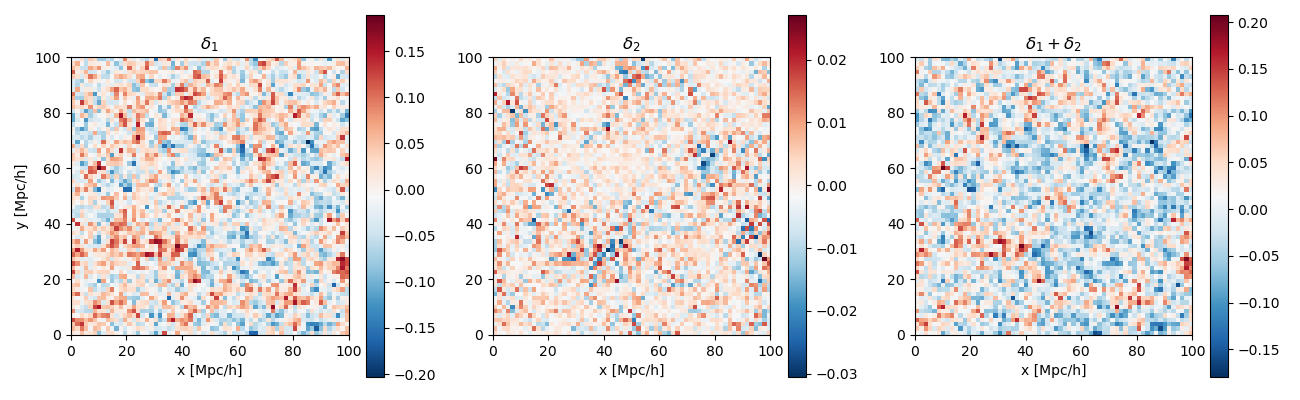

In [6]:
# Slices through z = 0: delta_1, delta_2 and delta_1 + delta_2
fig, ax = plt.subplots(1, 3, figsize=(13, 4))
for axi, field, title in zip(ax, [d1_x, d2_x, d1_x + d2_x],
                             [r"$\delta_1$", r"$\delta_2$", r"$\delta_1 + \delta_2$"]):
    im = axi.imshow(field[:, :, 0].T, origin="lower", extent=[0, L, 0, L], cmap="RdBu_r")
    fig.colorbar(im, ax=axi)
    axi.set_title(title)
    axi.set_xlabel("x [Mpc/h]")
ax[0].set_ylabel("y [Mpc/h]")
plt.tight_layout()
fig.savefig(f"{out_dir}/fig_slices.pdf")
plt.show()

$\delta_2$ is largest where $\delta_1$ has strong peaks and gradients: overdensities become higher and underdensities shallower (positive skewness).

## (b) Power spectrum and bispectrum: $\delta_1$ vs $\delta_1 + \delta_2$

- Power spectrum: $\hat P(k) = \frac{1}{N_kV}\sum_{k_a\in S_k}|\delta_{k_a}|^2$ (shells of width $k_f$, Exercise 3).
- Higher-order statistic: **bispectrum** of closed lattice triangles (eq. C.9), $\hat B_T = \frac{1}{N_TV}\sum_T \mathrm{Re}[\delta_{k_1}\delta_{k_2}\delta_{k_3}]$, with shells of width $\Delta k = 2k_f$, all below $k_\mathrm{Ny}/2$.

Two triangle sets: equilateral $k_1=k_2=k_3$, and $k_1=k_2=8k_f$ with varying $k_3$ (angle dependence).

In [7]:
# Triangle bins (shell width 2 k_f). Lattice triangles are listed once and reused for every realization.
dk = 2 * k_f
m_eq = [4, 6, 8, 10, 12, 14]              # equilateral: k / k_f
m_iso = [2, 4, 6, 8, 10, 12, 14]          # k1 = k2 = 8 k_f, k3 / k_f

tri_eq = [ex2.triangles(L, Ng, m * k_f, m * k_f, m * k_f, dk) for m in m_eq]
tri_iso = [ex2.triangles(L, Ng, 8 * k_f, 8 * k_f, m * k_f, dk) for m in m_iso]
print("triangles per equilateral bin:", [len(t["i1"]) for t in tri_eq])
print("triangles per k3 bin         :", [len(t["i1"]) for t in tri_iso])

# Tree-level prediction averaged over the same lattice triangles (eq. 6.15)
Bt_eq = np.array([ex2.btree_binned(t, P_lin) for t in tri_eq])
Bt_iso = np.array([ex2.btree_binned(t, P_lin) for t in tri_iso])

# Bin average vs the point value 12/7 P_L^2(k) of eq. 6.19
print("Btree(bin) / [12/7 P_L^2(k_center)]:", np.round(Bt_eq / (12 / 7 * P_lin(np.array(m_eq) * k_f)**2), 3))

triangles per equilateral bin: [39504, 129864, 327696, 648120, 1073616, 1634112]
triangles per k3 bin         : [72252, 161160, 240888, 327696, 410856, 487272, 543642]
Btree(bin) / [12/7 P_L^2(k_center)]: [1.43  1.172 1.098 1.055 1.037 1.023]


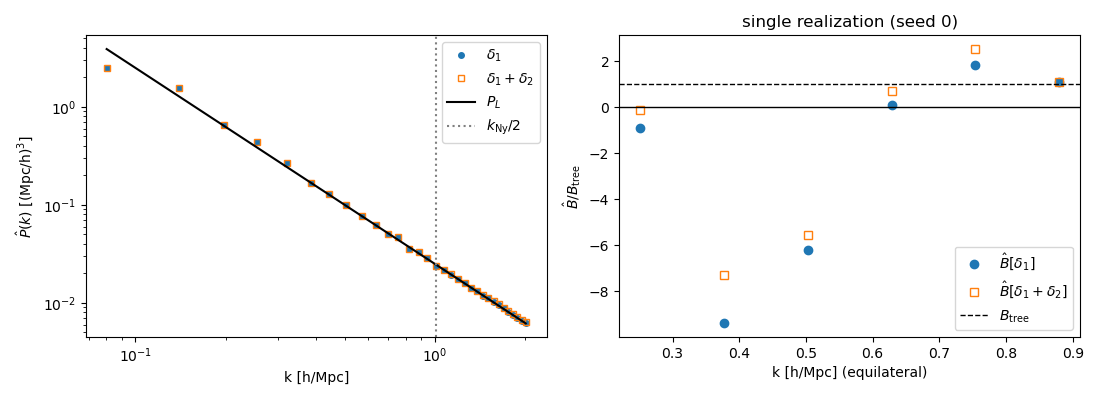

In [8]:
# One realization: power spectra and bispectra of delta_1 and delta_1 + delta_2
k_bin, P1_hat, _ = ex3.power_spectrum_from_k(d1_k, L, Ng // 2)
k_bin, P12_hat, _ = ex3.power_spectrum_from_k(d1_k + d2_k, L, Ng // 2)

B1_one = np.array([ex2.bispectrum(d1_k, t) for t in tri_eq])
B12_one = np.array([ex2.bispectrum(d1_k + d2_k, t) for t in tri_eq])

fig, ax = plt.subplots(1, 2, figsize=(11, 4))

# Power spectra
ax[0].loglog(k_bin, P1_hat, "o", ms=4, label=r"$\delta_1$")
ax[0].loglog(k_bin, P12_hat, "s", ms=4, mfc="none", label=r"$\delta_1+\delta_2$")
ax[0].loglog(k_bin, P_lin(k_bin), "k-", label=r"$P_L$")
ax[0].axvline(k_Ny / 2, color="gray", ls=":", label=r"$k_\mathrm{Ny}/2$")
ax[0].set_xlabel("k [h/Mpc]")
ax[0].set_ylabel(r"$\hat P(k)$ [(Mpc/h)$^3$]")
ax[0].legend()

# Equilateral bispectrum of this single realization
k_eq = np.array(m_eq) * k_f
ax[1].plot(k_eq, B1_one / Bt_eq, "o", label=r"$\hat B[\delta_1]$")
ax[1].plot(k_eq, B12_one / Bt_eq, "s", mfc="none", label=r"$\hat B[\delta_1+\delta_2]$")
ax[1].axhline(0, color="k", lw=1)
ax[1].axhline(1, color="k", ls="--", lw=1, label=r"$B_\mathrm{tree}$")
ax[1].set_xlabel("k [h/Mpc] (equilateral)")
ax[1].set_ylabel(r"$\hat B / B_\mathrm{tree}$")
ax[1].set_title(f"single realization (seed {seed})")
ax[1].legend()

plt.tight_layout()
fig.savefig(f"{out_dir}/fig_single_realization.pdf")
plt.show()

In one box the power spectra barely differ, and $\hat B$ scatters by several times $B_\mathrm{tree}$ for **both** fields: one finite box is dominated by sampling noise. An ensemble is needed (c).

## (c) Ensemble over realizations

$N_\mathrm{real} = 100$ seeds. For each seed we store $\hat P$ and $\hat B$ of $\delta_1$ and $\delta_1+\delta_2$ at several amplitudes $D$ (same phases: $\delta = D\delta_\mathrm{ref} + D^2\delta_{2,\mathrm{ref}}$), for use also in (d).

Since $\delta_1$ is kept, we can also form the **paired difference** $\hat B[\delta_1+\delta_2] - \hat B[\delta_1]$ on each realization, which removes the Gaussian sampling noise of $\delta_1$ while keeping the same mean ($\langle\delta_1\delta_1\delta_1\rangle = 0$).

In [9]:
N_real = 100
D_list = [0.25, 0.5, 1.0, 2.0]          # amplitudes; D = 0.5 is the default
tri_all = tri_eq + tri_iso              # all triangle bins (6 equilateral + 7 isosceles)

P1_all, P12_all = [], []                # power spectra at the default D: (N_real, n_k)
B1_all, B12_all = [], []                # bispectra: (N_real, n_D, n_bins)

t0 = time.time()
for s in range(N_real):
    d_ref = ex3.gaussian_field_k(L, Ng, A, n, seed=s)
    d2_ref = ex2.delta2_fft(d_ref, L)

    # Power spectra at the default amplitude
    P1_all.append(ex3.power_spectrum_from_k(D * d_ref, L, Ng // 2)[1])
    P12_all.append(ex3.power_spectrum_from_k(D * d_ref + D**2 * d2_ref, L, Ng // 2)[1])

    # Bispectra for every amplitude
    B1_all.append([[ex2.bispectrum(Dv * d_ref, t) for t in tri_all] for Dv in D_list])
    B12_all.append([[ex2.bispectrum(Dv * d_ref + Dv**2 * d2_ref, t) for t in tri_all] for Dv in D_list])

P1_all, P12_all = np.array(P1_all), np.array(P12_all)
B1_all, B12_all = np.array(B1_all), np.array(B12_all)
print(f"{N_real} realizations in {time.time() - t0:.0f} s")

# Save the raw measurements
np.savez(f"{out_dir}/ensemble.npz", k_bin=k_bin, P1=P1_all, P12=P12_all, B1=B1_all, B12=B12_all,
         D_list=D_list, m_eq=m_eq, m_iso=m_iso, L=L, Ng=Ng, A=A, n=n, dk=dk)

100 realizations in 96 s


In [10]:
# Ensemble mean and error of the mean, at the default amplitude
iD = D_list.index(D)
n_eq = len(tri_eq)
Bt_all = np.concatenate([Bt_eq, Bt_iso])

def mean_err(x):
    # Mean over realizations and its standard error
    return x.mean(axis=0), x.std(axis=0, ddof=1) / np.sqrt(len(x))

B1_m, B1_e = mean_err(B1_all[:, iD])                       # Gaussian field
B12_m, B12_e = mean_err(B12_all[:, iD])                    # delta_1 + delta_2
Bd_m, Bd_e = mean_err(B12_all[:, iD] - B1_all[:, iD])      # paired difference

# Gaussian test: mean in units of its error (should scatter as N(0, 1))
print("Gaussian B / error of mean:", np.round(B1_m / B1_e, 2))
# chi^2 over distinct bins: (8, 8, 8) k_f is both "eq 8" and "k3 = 8", count it once
unique = [i for i in range(len(B1_m)) if i != n_eq + m_iso.index(8)]
chi2 = np.sum((B1_m[unique] / B1_e[unique])**2)
print(f"chi^2 = {chi2:.1f} for {len(unique)} distinct bins (bins are correlated: same realizations)")

Gaussian B / error of mean: [-1.26 -2.07  0.39 -1.29 -1.14 -1.7  -1.11  0.15 -0.48  0.39 -1.03 -0.42
 -0.23]
chi^2 = 14.7 for 12 distinct bins (bins are correlated: same realizations)


In [11]:
# Table: ensemble results vs bin-averaged tree level (default amplitude)
labels = [f"eq {m}" for m in m_eq] + [f"k3 = {m}" for m in m_iso]
df_B = pd.DataFrame({"bin (k/k_f)": labels, "N_T": [len(t["i1"]) for t in tri_all],
                     "B1/err": B1_m / B1_e,
                     "B12/Btree": B12_m / Bt_all, "err12": B12_e / Bt_all,
                     "paired/Btree": Bd_m / Bt_all, "err_paired": Bd_e / Bt_all})
df_B.to_csv(f"{out_dir}/bispectrum_ensemble.csv", index=False)
df_B.round(3)

,bin (k/k_f),N_T,B1/err,B12/Btree,err12,paired/Btree,err_paired
0,eq 4,39504,-1.262,-0.315,1.034,0.991,0.049
1,eq 6,129864,-2.070,-0.562,0.782,1.020,0.068
2,eq 8,327696,0.386,1.356,0.775,1.056,0.064
3,eq 10,648120,-1.291,0.199,0.677,1.069,0.076
4,eq 12,1073616,-1.145,0.203,0.628,0.930,0.084
5,eq 14,1634112,-1.699,-0.151,0.620,0.901,0.085
6,k3 = 2,72252,-1.112,0.835,0.155,1.005,0.029
7,k3 = 4,161160,0.150,1.038,0.261,1.000,0.024
8,k3 = 6,240888,-0.478,0.795,0.399,0.985,0.030
9,k3 = 8,327696,0.386,1.356,0.775,1.056,0.064


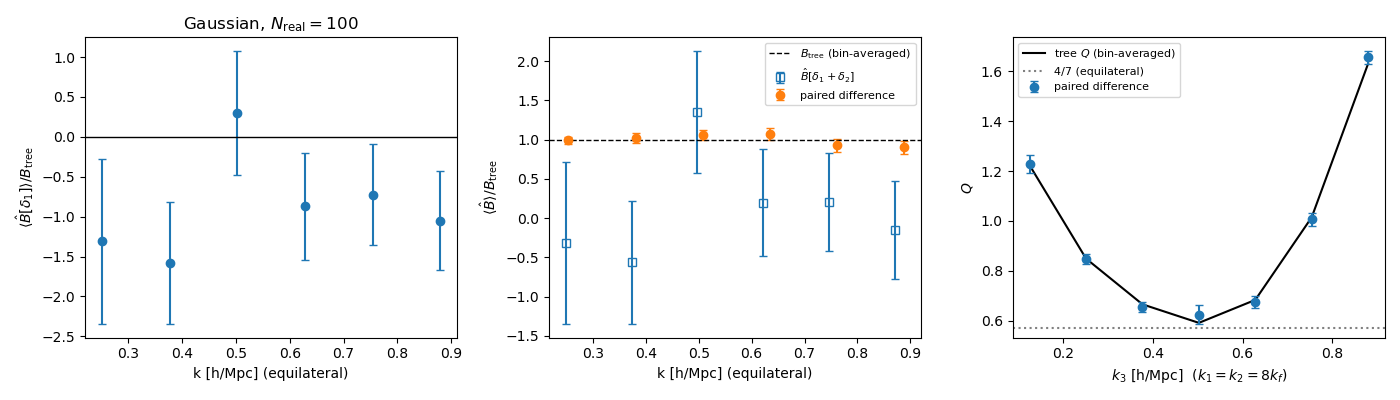

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4))

# Left: Gaussian field, mean +- error (in units of B_tree, only to set the scale)
ax[0].errorbar(k_eq, B1_m[:n_eq] / Bt_eq, B1_e[:n_eq] / Bt_eq, fmt="o", capsize=3)
ax[0].axhline(0, color="k", lw=1)
ax[0].set_xlabel("k [h/Mpc] (equilateral)")
ax[0].set_ylabel(r"$\langle\hat B[\delta_1]\rangle / B_\mathrm{tree}$")
ax[0].set_title(rf"Gaussian, $N_\mathrm{{real}}={N_real}$")

# Middle: equilateral, delta_1 + delta_2 (direct and paired) vs tree level
ax[1].errorbar(k_eq * 0.99, B12_m[:n_eq] / Bt_eq, B12_e[:n_eq] / Bt_eq, fmt="s", mfc="none",
               capsize=3, label=r"$\hat B[\delta_1+\delta_2]$")
ax[1].errorbar(k_eq * 1.01, Bd_m[:n_eq] / Bt_eq, Bd_e[:n_eq] / Bt_eq, fmt="o", capsize=3,
               label="paired difference")
ax[1].axhline(1, color="k", ls="--", lw=1, label=r"$B_\mathrm{tree}$ (bin-averaged)")
ax[1].set_xlabel("k [h/Mpc] (equilateral)")
ax[1].set_ylabel(r"$\langle\hat B\rangle / B_\mathrm{tree}$")
ax[1].legend(fontsize=8)

# Right: reduced bispectrum Q (eq. 6.20) for k1 = k2 = 8 k_f, as a function of k3
def P_products(tri):
    # Bin average of P(k1)P(k2) + P(k2)P(k3) + P(k3)P(k1), same triangles as B
    kk = [k_f * np.sqrt(np.sum(tri[s]**2, axis=1)) for s in ("n1", "n2", "n3")]
    P1, P2, P3 = (P_lin(x) for x in kk)
    return np.mean(P1 * P2 + P2 * P3 + P3 * P1)

norm_iso = np.array([P_products(t) for t in tri_iso])
k3 = np.array(m_iso) * k_f
ax[2].plot(k3, Bt_iso / norm_iso, "k-", label=r"tree $Q$ (bin-averaged)")
ax[2].errorbar(k3, Bd_m[n_eq:] / norm_iso, Bd_e[n_eq:] / norm_iso, fmt="o", capsize=3, label="paired difference")
ax[2].axhline(4 / 7, color="gray", ls=":", label="4/7 (equilateral)")
ax[2].set_xlabel(r"$k_3$ [h/Mpc]  ($k_1=k_2=8k_f$)")
ax[2].set_ylabel(r"$Q$")
ax[2].legend(fontsize=8)

plt.tight_layout()
fig.savefig(f"{out_dir}/fig_bispectrum_ensemble.pdf")
plt.show()

- **Gaussian**: $\langle\hat B[\delta_1]\rangle$ is consistent with zero within the error of the mean ($\chi^2$ above): a single box is not zero, but the ensemble is.
- **$\delta_1+\delta_2$**: the ensemble mean agrees with the bin-averaged $B_\mathrm{tree}$, but with large errors (Gaussian noise). The paired difference gives the same mean with much smaller errors, and follows the triangle shape of $Q$ (minimum near the equilateral $4/7$, larger for squeezed and collinear triangles).
- Bin averaging matters: with $\Delta k = 2k_f$ and $P_L^2\propto k^{-4}$, $B_\mathrm{tree}$(bin) exceeds $\frac{12}{7}P_L^2(k_\mathrm{center})$ by 43% at $k=4k_f$ and 2% at $14k_f$, so the prediction must be averaged over the same triangles.

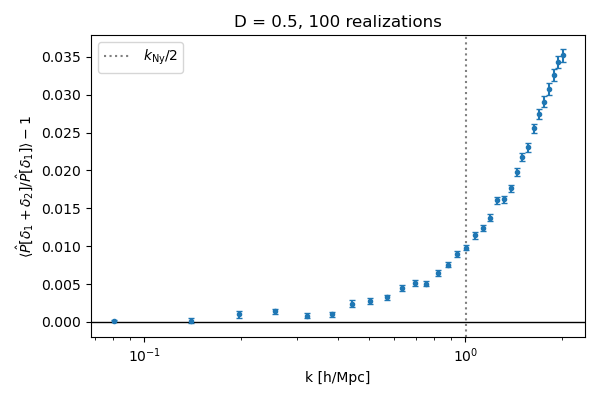

In [13]:
# Power spectrum: ensemble ratio P[delta_1 + delta_2] / P[delta_1] - 1 (contains P22 and the noisy cross term 2 P12)
ratio = P12_all / P1_all - 1
r_m, r_e = mean_err(ratio)

fig, ax = plt.subplots(figsize=(6, 4))
ax.errorbar(k_bin, r_m, r_e, fmt="o", ms=3, capsize=2)
ax.axhline(0, color="k", lw=1)
ax.axvline(k_Ny / 2, color="gray", ls=":", label=r"$k_\mathrm{Ny}/2$")
ax.set_xscale("log")
ax.set_xlabel("k [h/Mpc]")
ax.set_ylabel(r"$\langle \hat P[\delta_1+\delta_2] / \hat P[\delta_1]\rangle - 1$")
ax.set_title(f"D = {D}, {N_real} realizations")
ax.legend()
plt.tight_layout()
fig.savefig(f"{out_dir}/fig_power_ratio.pdf")
plt.show()

$\hat P[\delta_1+\delta_2] = \hat P_{11} + 2\hat P_{12} + \hat P_{22}$: $P_{12}$ has zero mean (three Gaussian fields, eq. 7.3), so the ensemble shift is $P_{22} > 0$, a few % here and growing with $k$ relative to $P_L$. This is not a consistent one-loop spectrum: $\delta_3$ (and $2P_{13}$) is missing (see the supplementary part).

## (d) Resolution, box size, realization scatter and amplitude

Only well-resolved bins are used: every shell lies below $k_\mathrm{Ny}/2$ of the coarsest mesh.

**Input amplitude.** The same phases at each $D$. Expected scalings: $B_\mathrm{tree}\propto D^4$; Gaussian noise $\propto D^3$, so the S/N of $\hat B[\delta_1+\delta_2]$ grows $\propto D$; the paired estimator contains $3D^4\delta_1\delta_1\delta_2$ (signal + noise), $3D^5\delta_1\delta_2\delta_2$ (zero mean, noise) and $D^6\delta_2\delta_2\delta_2$ (non-zero mean), so its S/N is roughly independent of $D$ and departures from tree level are expected at order $D^2$ (i.e. $\sigma_1^2$).

In [14]:
# Amplitude test (equilateral bins), using the same realizations at every D
rows = []
for j, Dv in enumerate(D_list):
    Bt_D = np.array([ex2.btree_binned(t, lambda k: P_lin(k, Dv)) for t in tri_eq])
    m12, e12 = mean_err(B12_all[:, j, :n_eq])
    md_, ed_ = mean_err(B12_all[:, j, :n_eq] - B1_all[:, j, :n_eq])
    sigma = D_list[j] / D * np.std(d1_x)                       # rms of delta_1 at this D
    rows.append({"D": Dv, "sigma_1": sigma,
                 "S/N direct (mean over bins)": np.mean(m12 / e12),
                 "S/N paired (mean over bins)": np.mean(md_ / ed_),
                 "paired/Btree (k=4k_f)": md_[0] / Bt_D[0],
                 "paired/Btree (k=14k_f)": md_[-1] / Bt_D[-1]})
df_amp = pd.DataFrame(rows)
df_amp.to_csv(f"{out_dir}/amplitude_test.csv", index=False)
df_amp.round(4)

,D,sigma_1,S/N direct (mean over bins),S/N paired (mean over bins),paired/Btree (k=4k_f),paired/Btree (k=14k_f)
0,0.25,0.0276,-0.4983,14.5833,0.9914,0.9042
1,0.50,0.0553,0.1835,14.5696,0.9914,0.9014
2,1.00,0.1106,1.5333,14.5638,0.9928,0.9065
3,2.00,0.2211,4.0892,14.6334,1.0006,0.9595


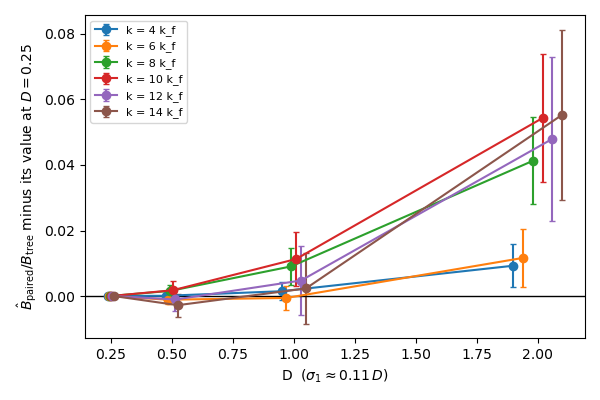

In [15]:
# Change of the paired estimator w.r.t. the smallest amplitude, realization by realization.
# The leading noise is common to all D (same phases), so this isolates the amplitude dependence.
Bt_D = {Dv: np.array([ex2.btree_binned(t, lambda k: P_lin(k, Dv)) for t in tri_eq]) for Dv in D_list}
paired = {Dv: (B12_all[:, j, :n_eq] - B1_all[:, j, :n_eq]) / Bt_D[Dv] for j, Dv in enumerate(D_list)}

fig, ax = plt.subplots(figsize=(6, 4))
for i, m in enumerate(m_eq):
    ch_m, ch_e = mean_err(np.array([paired[Dv][:, i] - paired[D_list[0]][:, i] for Dv in D_list]).T)
    ax.errorbar(np.array(D_list) * (1 + 0.02 * (i - 2.5)), ch_m, ch_e, fmt="o-", capsize=2, label=f"k = {m} k_f")
ax.axhline(0, color="k", lw=1)
ax.set_xlabel(r"D  ($\sigma_1 \approx 0.11\,D$)")
ax.set_ylabel(r"$\hat B_\mathrm{paired}/B_\mathrm{tree}$ minus its value at $D=0.25$")
ax.legend(fontsize=8)
plt.tight_layout()
fig.savefig(f"{out_dir}/fig_amplitude.pdf")
plt.show()

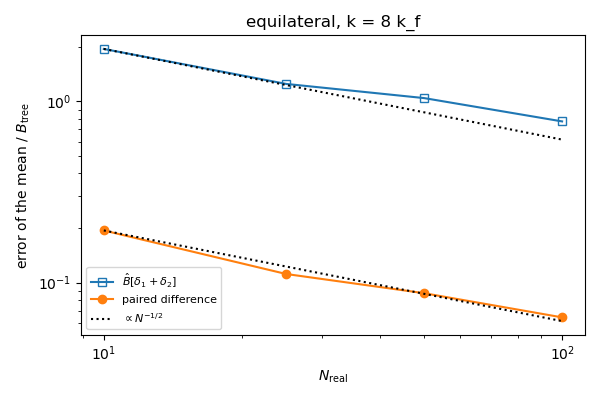

In [16]:
# Realization scatter: error of the mean vs N_real (equilateral k = 8 k_f, default D)
i8 = m_eq.index(8)
N_list = [10, 25, 50, 100]
err_direct = [B12_all[:N, iD, i8].std(ddof=1) / np.sqrt(N) / Bt_eq[i8] for N in N_list]
err_paired = [(B12_all[:N, iD, i8] - B1_all[:N, iD, i8]).std(ddof=1) / np.sqrt(N) / Bt_eq[i8] for N in N_list]

fig, ax = plt.subplots(figsize=(6, 4))
ax.loglog(N_list, err_direct, "s-", mfc="none", label=r"$\hat B[\delta_1+\delta_2]$")
ax.loglog(N_list, err_paired, "o-", label="paired difference")
N_arr = np.array(N_list)
ax.loglog(N_arr, err_direct[0] * (N_arr / 10)**-0.5, "k:", label=r"$\propto N^{-1/2}$")
ax.loglog(N_arr, err_paired[0] * (N_arr / 10)**-0.5, "k:")
ax.set_xlabel(r"$N_\mathrm{real}$")
ax.set_ylabel(r"error of the mean / $B_\mathrm{tree}$")
ax.set_title("equilateral, k = 8 k_f")
ax.legend(fontsize=8)
plt.tight_layout()
fig.savefig(f"{out_dir}/fig_realizations.pdf")
plt.show()

**Resolution and box size.** Physical bins $k = 4, 6, 8\times(2\pi/100)$ h/Mpc, width $2\times(2\pi/100)$, equilateral, paired estimator, default $D$.
- Resolution: $L = 100$ Mpc/h with $N_g = 32, 64, 128$.
- Box size at fixed cell size $L/N_g$: $(L, N_g) = (50, 32), (100, 64), (200, 128)$.

In [17]:
def run_box(L_b, Ng_b, N_b, m_list=(4, 6, 8)):
    # Equilateral paired bispectrum over N_b realizations for one (L, Ng); bins in units of 2 pi / 100
    k_unit = 2 * np.pi / 100.0
    tris = [ex2.triangles(L_b, Ng_b, m * k_unit, m * k_unit, m * k_unit, 2 * k_unit) for m in m_list]
    Bt = np.array([ex2.btree_binned(t, P_lin) for t in tris])
    diff = []
    for s in range(N_b):
        d_ref = ex3.gaussian_field_k(L_b, Ng_b, A, n, seed=1000 + s)
        d2_ref = ex2.delta2_fft(d_ref, L_b)
        diff.append([ex2.bispectrum(D * d_ref + D**2 * d2_ref, t) - ex2.bispectrum(D * d_ref, t) for t in tris])
    m, e = mean_err(np.array(diff))
    return [{"L": L_b, "Ng": Ng_b, "N_real": N_b, "k/(2pi/100)": mm, "N_T": len(t["i1"]),
             "paired/Btree": m[i] / Bt[i], "err": e[i] / Bt[i]} for i, (mm, t) in enumerate(zip(m_list, tris))]

t0 = time.time()
rows = []
for L_b, Ng_b, N_b in [(100, 32, 40), (100, 64, 40), (100, 128, 20), (50, 32, 40), (200, 128, 20)]:
    rows += run_box(L_b, Ng_b, N_b)
df_box = pd.DataFrame(rows)
df_box.to_csv(f"{out_dir}/resolution_box_test.csv", index=False)
print(f"done in {time.time() - t0:.0f} s")
df_box.round(3)

done in 321 s


,L,Ng,N_real,k/(2pi/100),N_T,paired/Btree,err
0,100,32,40,4,39504,0.977,0.069
1,100,32,40,6,129864,1.043,0.085
2,100,32,40,8,327696,1.117,0.076
3,100,64,40,4,39504,0.961,0.073
4,100,64,40,6,129864,1.164,0.079
5,100,64,40,8,327696,0.991,0.103
6,100,128,20,4,39504,1.018,0.149
7,100,128,20,6,129864,0.958,0.116
8,100,128,20,8,327696,0.792,0.129
9,50,32,40,4,912,0.950,0.129


**Discussion**
- **Amplitude**: for $D \le 1$ ($\sigma_1 \le 0.11$) the paired estimator does not change within $\lesssim 1\%$ errors; at $D=2$ ($\sigma_1 \approx 0.22$) it rises by 4-6% at $k \ge 8k_f$ (2-3$\sigma$): the higher-order terms appear as the linear variance grows. The S/N of the direct estimator grows $\propto D$, the paired one stays constant (table).
- **Resolution**: at fixed $L$ the mean is unchanged within errors (scattered by up to $\sim2\sigma$ with 20-40 realizations): the tree-level contraction only involves the triangle modes, which all meshes resolve. A finer mesh adds short modes to $\delta_2$, which slightly increase the scatter per realization (Ng = 128).
- **Box size**: a larger $V$ gives more triangles per physical bin ($N_T\propto V$), so the error per realization falls roughly as $V^{-1/2}$; a small box has few, coarse triangles and a large scatter.
- **Realization scatter**: errors fall as $N_\mathrm{real}^{-1/2}$ for both estimators; the paired one is 7-20 times lower.
- **Signal vs noise**: the non-Gaussian signal is a *mean* $\propto D^4$, the same for every realization and fixed by $F_2$; finite-sampling noise has zero mean, scales as $D^3$ (Gaussian part) and averages down with $N_T$ and $N_\mathrm{real}$. A non-zero $\hat B$ in one box (b) is noise; only a shift of the ensemble mean, with the triangle shape of $B_\mathrm{tree}$, is gravitational non-Gaussianity.

## Supplementary: one-loop power spectrum

$P_\mathrm{1\text{-}loop} = P_L + P_{22} + 2P_{13}$, with eqs. 7.17-7.18 in $r = q/k$, $\nu = \hat q\cdot\hat k$:
- $r$ on a log grid (trapezoid in $\ln r$), $\nu$ with Gauss-Legendre nodes;
- $P_{22}$: integrand symmetric under $q\leftrightarrow k-q$, so we integrate only $|q|<|k-q|$ and double it; the region $|k-q|\to0$ becomes $q\to0$, controlled by the IR cutoff $k_\mathrm{min}$;
- $F_3^{(s)}(k,q,-q)$ from the recursion (eq. A.9), symmetrized over the 6 permutations.

Continuum spectrum $P_L = A k^n$ ($D=1$), cutoffs $k_\mathrm{min} < q < k_\mathrm{max}$.

In [18]:
P_ref = lambda k: A * k**n           # n = -2, D = 1
k_test = 0.2                         # [h/Mpc]

# 1) Sampling of the (r, nu) grid
for nr, nnu in [(500, 16), (1000, 32), (2000, 64), (4000, 128)]:
    s22 = ex2.P22(k_test, P_ref, 1e-4, 100 * k_test, nr, nnu)
    s13 = ex2.P13(k_test, P_ref, 1e-4, 100 * k_test, nr, nnu)
    naive = ex2.P22(k_test, P_ref, 1e-4, 100 * k_test, nr, nnu, symmetric=False)
    print(f"nr = {nr:4d}, nnu = {nnu:3d}:  (P22 + 2P13)/P_L = {(s22 + 2 * s13) / P_ref(k_test):.8f}   "
          f"P22/P_L = {s22 / P_ref(k_test):.6f}   naive P22/P_L = {naive / P_ref(k_test):.6f}")

nr =  500, nnu =  16:  (P22 + 2P13)/P_L = 0.00140334   P22/P_L = 0.676463   naive P22/P_L = 0.339881
nr = 1000, nnu =  32:  (P22 + 2P13)/P_L = 0.00140361   P22/P_L = 0.676438   naive P22/P_L = 0.341152
nr = 2000, nnu =  64:  (P22 + 2P13)/P_L = 0.00140368   P22/P_L = 0.676432   naive P22/P_L = 0.343642
nr = 4000, nnu = 128:  (P22 + 2P13)/P_L = 0.00140369   P22/P_L = 0.676431   naive P22/P_L = 0.348590


The symmetrized integral converges with the grid; the naive one (full $\nu$ range, nothing controlling $|k-q|\to0$) does not, and is far from the correct value.

In [19]:
# 2) Infrared cutoff: P22 and 2P13 separately vs their sum
rows = []
for kmin in [1e-1, 1e-2, 1e-3, 1e-4, 1e-5]:
    s22 = ex2.P22(k_test, P_ref, kmin * k_test, 100 * k_test)
    s13 = ex2.P13(k_test, P_ref, kmin * k_test, 100 * k_test)
    rows.append({"kmin/k": kmin, "P22/P_L": s22 / P_ref(k_test), "2P13/P_L": 2 * s13 / P_ref(k_test),
                 "(P22+2P13)/P_L": (s22 + 2 * s13) / P_ref(k_test)})
df_ir = pd.DataFrame(rows)
df_ir.to_csv(f"{out_dir}/loop_ir_test.csv", index=False)
df_ir

,kmin/k,P22/P_L,2P13/P_L,(P22+2P13)/P_L
0,0.10000,0.004103,-0.002966,0.001137
1,0.01000,0.034707,-0.033329,0.001378
2,0.00100,0.338693,-0.337290,0.001402
3,0.00010,3.378343,-3.376938,0.001405
4,0.00001,33.774868,-33.773462,0.001405


For $n=-2$, $P_{22}$ and $2P_{13}$ each grow as $1/k_\mathrm{min}$ (large-scale displacements), but their sum is stable to $\sim10^{-6}$: the equivalence-principle cancellation (notes 7.5). It needs high accuracy in each piece, since we subtract numbers $\sim 10^4$ times larger than the result.

In [20]:
# 3) Ultraviolet cutoff: n = -2 (convergent) vs n = -1 (P13 sensitive to short modes)
for n_uv in [-2.0, -1.0]:
    P_uv = lambda k: A * k**n_uv
    for kmax in [10, 100, 1000]:
        s22 = ex2.P22(k_test, P_uv, 1e-4 * k_test, kmax * k_test)
        s13 = ex2.P13(k_test, P_uv, 1e-4 * k_test, kmax * k_test)
        print(f"n = {n_uv:+.0f}, kmax/k = {kmax:4d}:  P22/P_L = {s22 / P_uv(k_test):.6e}   "
              f"2P13/P_L = {2 * s13 / P_uv(k_test):.6e}")

n = -2, kmax/k =   10:  P22/P_L = 3.378339e+00   2P13/P_L = -3.376916e+00
n = -2, kmax/k =  100:  P22/P_L = 3.378343e+00   2P13/P_L = -3.376938e+00
n = -2, kmax/k = 1000:  P22/P_L = 3.378347e+00   2P13/P_L = -3.376944e+00
n = -1, kmax/k =   10:  P22/P_L = 6.497003e-04   2P13/P_L = -6.837110e-04
n = -1, kmax/k =  100:  P22/P_L = 6.497041e-04   2P13/P_L = -7.740306e-04
n = -1, kmax/k = 1000:  P22/P_L = 6.497041e-04   2P13/P_L = -8.643879e-04


In [21]:
# 4) Units: same calculation with k in 1/Mpc and P in Mpc^3 (h = 0.7). Must give P / h^3 at k = h k_h.
h = 0.7
P_Mpc = lambda k: P_ref(k / h) / h**3                  # P(k) in Mpc^3 with k in 1/Mpc
loop_h = ex2.P22(k_test, P_ref, 1e-4 * k_test, 100 * k_test) + 2 * ex2.P13(k_test, P_ref, 1e-4 * k_test, 100 * k_test)
loop_M = (ex2.P22(h * k_test, P_Mpc, 1e-4 * h * k_test, 100 * h * k_test)
          + 2 * ex2.P13(h * k_test, P_Mpc, 1e-4 * h * k_test, 100 * h * k_test))
print(f"(P22 + 2P13) in Mpc^3 * h^3 / value in (Mpc/h)^3 = {loop_M * h**3 / loop_h:.12f}")

(P22 + 2P13) in Mpc^3 * h^3 / value in (Mpc/h)^3 = 1.000000000000


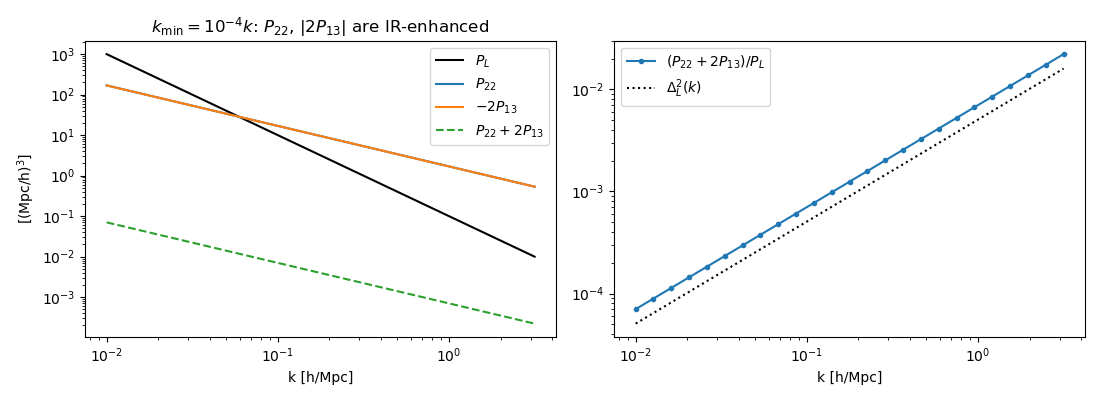

In [22]:
# One-loop spectrum vs k (n = -2, cutoffs kmin = 1e-4 k, kmax = 100 k)
k_arr = np.logspace(-2, 0.5, 25)
p22 = np.array([ex2.P22(k, P_ref, 1e-4 * k, 100 * k) for k in k_arr])
p13 = np.array([ex2.P13(k, P_ref, 1e-4 * k, 100 * k) for k in k_arr])
Delta2 = k_arr**3 * P_ref(k_arr) / (2 * np.pi**2)       # dimensionless linear power (eq. 8.2)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].loglog(k_arr, P_ref(k_arr), "k-", label=r"$P_L$")
ax[0].loglog(k_arr, p22, label=r"$P_{22}$")
ax[0].loglog(k_arr, -2 * p13, label=r"$-2P_{13}$")
ax[0].loglog(k_arr, p22 + 2 * p13, "--", label=r"$P_{22}+2P_{13}$")
ax[0].set_xlabel("k [h/Mpc]")
ax[0].set_ylabel(r"[(Mpc/h)$^3$]")
ax[0].set_title(r"$k_\mathrm{min} = 10^{-4}k$: $P_{22}$, $|2P_{13}|$ are IR-enhanced")
ax[0].legend()

ax[1].loglog(k_arr, (p22 + 2 * p13) / P_ref(k_arr), "o-", ms=3, label=r"$(P_{22}+2P_{13})/P_L$")
ax[1].loglog(k_arr, Delta2, "k:", label=r"$\Delta^2_L(k)$")
ax[1].set_xlabel("k [h/Mpc]")
ax[1].legend()

plt.tight_layout()
fig.savefig(f"{out_dir}/fig_one_loop.pdf")
plt.show()

**Discussion**
- **Numerical convergence** (grid, IR cutoff, $|k-q|\to0$, units) is a property of the integration: it can be pushed to $\lesssim10^{-5}$.
- **Short-scale sensitivity** is physical: the loop integrates over all $q$, including $q \gtrsim k_\mathrm{NL}$ where SPT is not valid (notes 7.6). For $n=-2$ the result does not depend on $k_\mathrm{max}$; for $n=-1$, $P_{13}$ changes logarithmically with $k_\mathrm{max}$, so a converged number still depends on unresolved physics (this is what the EFT counterterm absorbs).
- $(P_{22}+2P_{13})/P_L$ follows $\Delta_L^2(k)$, i.e. the one-loop term is suppressed by the linear power, as expected for a fourth-order correction.